# Performance Engineering & Benchmark Analysis Report
## NYC TLC Yellow Taxi Analytics (ComPar 26/27)

Este notebook carrega automaticamente os ficheiros JSON exportados pelo `SparkProfiler` (em `output/benchmarks/profiling_*.json` e `output/profiling_report.json`) e gera:
1. **Tabelas formatadas** (com *Speedup*, redução percentual, utilização de CPU, GC, Memória de Pico, Shuffle e *Skew*), incluindo exportação direta para **Markdown** e **LaTeX**.
2. **Gráficos de Engenharia de Performance** (evolução do *Wall Time* e *Speedup*, decomposição CPU vs GC vs I/O, Memória de Pico e Volume de Shuffle, e número de Stages/Tasks).
3. **Diagnóstico por Stage (Stage Breakdown & Task Skew)**.
4. **Visualização Analítica dos Resultados (M2 Parquet)**: *heatmaps* horários/semanais por *Borough* e perfis temporais de tarifas e duração.

### 1. Carregamento Automático dos JSONs de Benchmark

In [1]:
import os
import re
import glob
import json
import subprocess
import sys

# Garante que matplotlib, seaborn e tabulate estao instalados no ambiente do notebook
for pkg in ["matplotlib", "seaborn", "tabulate"]:
    try:
        __import__(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 200
sns.set_theme(style="whitegrid", palette="deep")

# Deteta diretoria de output quer estejas no container Jupyter (/output) ou localmente (../output)
BASE_OUTPUT = "/output" if os.path.exists("/output") else ("../output" if os.path.exists("../output") else "output")
PLOTS_DIR = os.path.join(BASE_OUTPUT, "plots")
os.makedirs(PLOTS_DIR, exist_ok=True)

def fmt_bytes(b):
    n = float(b)
    for unit in ["B", "KB", "MB", "GB", "TB"]:
        if abs(n) < 1024.0:
            return f"{n:.1f} {unit}"
        n /= 1024.0
    return f"{n:.1f} PB"

def natural_key(s):
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r"(\d+)", str(s))]

def load_benchmark_jsons(base_dir):
    bench_files = sorted(glob.glob(os.path.join(base_dir, "benchmarks", "profiling_*.json")), key=natural_key)
    single_file = os.path.join(base_dir, "profiling_report.json")
    if not bench_files and os.path.exists(single_file):
        bench_files = [single_file]

    run_rows = []
    stage_rows = []

    for fpath in bench_files:
        fname = os.path.basename(fpath)
        label = re.sub(r"^profiling_|\.json$", "", fname)
        if label == "report":
            label = "latest"

        with open(fpath, "r", encoding="utf-8") as f:
            data = json.load(f)

        for op_name, m in data.items():
            exec_run_s = m.get("executorRunTimeMs", 0) / 1000.0
            exec_cpu_s = m.get("executorCpuTimeMs", 0) / 1000.0
            gc_s = m.get("jvmGcTimeMs", 0) / 1000.0
            io_wait_s = max(0.0, exec_run_s - exec_cpu_s - gc_s)
            cpu_eff_pct = (exec_cpu_s / exec_run_s * 100.0) if exec_run_s > 0 else 0.0

            run_rows.append({
                "file": fname,
                "version": label,
                "operation": op_name,
                "wall_time_s": m.get("wallTimeS", 0.0),
                "num_jobs": m.get("numJobs", 0),
                "num_stages": m.get("numStages", 0),
                "num_tasks": m.get("numTasks", 0),
                "exec_run_s": exec_run_s,
                "exec_cpu_s": exec_cpu_s,
                "jvm_gc_s": gc_s,
                "io_wait_s": io_wait_s,
                "cpu_efficiency_pct": cpu_eff_pct,
                "peak_mem_bytes": m.get("peakExecutionMemoryBytes", 0),
                "peak_mem_mb": m.get("peakExecutionMemoryBytes", 0) / (1024.0 ** 2),
                "input_bytes": m.get("inputBytes", 0),
                "output_bytes": m.get("outputBytes", 0),
                "shuffle_read_bytes": m.get("shuffleReadBytes", 0),
                "shuffle_write_bytes": m.get("shuffleWriteBytes", 0),
                "total_shuffle_mb": (m.get("shuffleReadBytes", 0) + m.get("shuffleWriteBytes", 0)) / (1024.0 ** 2),
                "mem_spill_bytes": m.get("memorySpilledBytes", 0),
                "disk_spill_bytes": m.get("diskSpilledBytes", 0),
                "median_task_ms": m.get("medianTaskDurationMs", 0),
                "max_task_ms": m.get("maxTaskDurationMs", 0),
                "skew_ratio": m.get("skewRatio", 1.0)
            })

            for st in m.get("stages", []):
                stage_rows.append({
                    "version": label,
                    "operation": op_name,
                    "stage_id": st.get("stageId", -1),
                    "stage_name": re.sub(r"<[^>]+>", " ", st.get("name", ""))[:45],
                    "num_tasks": st.get("numTasks", 0),
                    "run_time_ms": st.get("executorRunTimeMs", 0),
                    "cpu_time_ms": st.get("executorCpuTimeMs", 0),
                    "gc_time_ms": st.get("jvmGcTimeMs", 0),
                    "peak_mem_mb": st.get("peakExecutionMemoryBytes", 0) / (1024.0 ** 2),
                    "shuffle_read_kb": st.get("shuffleReadBytes", 0) / 1024.0,
                    "shuffle_write_kb": st.get("shuffleWriteBytes", 0) / 1024.0,
                    "med_task_ms": st.get("medianTaskDurationMs", 0),
                    "max_task_ms": st.get("maxTaskDurationMs", 0),
                    "skew_ratio": st.get("skewRatio", 1.0),
                    "skew_warning": st.get("hasSignificantSkew", False)
                })

    return pd.DataFrame(run_rows), pd.DataFrame(stage_rows), bench_files

df_runs, df_stages, loaded_files = load_benchmark_jsons(BASE_OUTPUT)
print(f"Ficheiros JSON carregados ({len(loaded_files)}): {[os.path.basename(f) for f in loaded_files]}")
print(f"Operacoes encontradas: {df_runs['operation'].unique().tolist() if not df_runs.empty else 'Nenhuma'}")

Ficheiros JSON carregados (8): ['profiling_M2v0.json', 'profiling_M2v1.json', 'profiling_M2v2.json', 'profiling_M2v3.json', 'profiling_M2v4.json', 'profiling_M2v5.json', 'profiling_M2v6.json', 'profiling_M2v7.json']
Operacoes encontradas: ['M1_ingestion_and_cleaning', 'M2_temporal_demand']


### 2. Tabelas Comparativas Formatadas (HTML Estilizado + Markdown + LaTeX)

Gera uma tabela resumo para cada operação analisada, calculando automaticamente o **Speedup** e a **Redução de Tempo (%)** face à primeira versão (baseline).

In [2]:
def build_formatted_table(df_op):
    df_op = df_op.copy().reset_index(drop=True)
    base_wall = df_op.loc[0, "wall_time_s"] if len(df_op) > 0 and df_op.loc[0, "wall_time_s"] > 0 else 1.0

    df_op["speedup"] = base_wall / df_op["wall_time_s"].replace(0, np.nan)
    df_op["time_saved_pct"] = (1.0 - df_op["wall_time_s"] / base_wall) * 100.0

    summary = pd.DataFrame({
        "Version": df_op["version"],
        "Wall Time (s)": df_op["wall_time_s"].map(lambda x: f"{x:.2f}s"),
        "Speedup": df_op["speedup"].map(lambda x: f"{x:.2f}x"),
        "Delta (%)": df_op["time_saved_pct"].map(lambda x: f"{-x:+.1f}%" if abs(x) > 0.01 else "baseline"),
        "Stages": df_op["num_stages"],
        "Tasks": df_op["num_tasks"],
        "Exec Run (s)": df_op["exec_run_s"].map(lambda x: f"{x:.2f}s"),
        "CPU Time (s)": df_op["exec_cpu_s"].map(lambda x: f"{x:.2f}s"),
        "CPU Eff (%)": df_op["cpu_efficiency_pct"].map(lambda x: f"{x:.1f}%"),
        "GC Time (s)": df_op["jvm_gc_s"].map(lambda x: f"{x:.2f}s"),
        "Peak Mem": df_op["peak_mem_bytes"].map(fmt_bytes),
        "Shuffle Read": df_op["shuffle_read_bytes"].map(fmt_bytes),
        "Shuffle Write": df_op["shuffle_write_bytes"].map(fmt_bytes),
        "Disk Spill": df_op["disk_spill_bytes"].map(fmt_bytes),
        "Task Skew": df_op["skew_ratio"].map(lambda x: f"{x:.1f}x")
    })
    return summary, df_op

if not df_runs.empty:
    for op_name, group in df_runs.groupby("operation", sort=False):
        display(Markdown(f"#### Operação: `{op_name}`"))
        summary_tbl, numeric_df = build_formatted_table(group)
        display(summary_tbl)

        print("\n--- Tabela Markdown (pronta a copiar para o relatorio) ---")
        print(summary_tbl.to_markdown(index=False))
        print("\n" + "=" * 90 + "\n")

#### Operação: `M1_ingestion_and_cleaning`

,Version,Wall Time (s),Speedup,Delta (%),Stages,Tasks,Exec Run (s),CPU Time (s),CPU Eff (%),GC Time (s),Peak Mem,Shuffle Read,Shuffle Write,Disk Spill,Task Skew
0,M2v0,5.17s,1.00x,baseline,5,11,5.01s,2.96s,59.2%,0.18s,32.2 MB,757.0 B,757.0 B,0.0 B,2.2x
1,M2v1,5.71s,0.91x,+10.4%,5,11,5.03s,2.90s,57.7%,0.17s,32.2 MB,757.0 B,757.0 B,0.0 B,2.7x
2,M2v2,5.75s,0.90x,+11.2%,5,11,5.09s,2.94s,57.8%,0.18s,32.2 MB,757.0 B,757.0 B,0.0 B,2.6x
3,M2v3,5.26s,0.98x,+1.7%,5,11,5.17s,2.98s,57.7%,0.23s,32.2 MB,757.0 B,757.0 B,0.0 B,2.2x
4,M2v4,5.26s,0.98x,+1.7%,5,11,5.36s,3.04s,56.7%,0.20s,32.2 MB,757.0 B,757.0 B,0.0 B,2.2x
5,M2v5,5.72s,0.90x,+10.6%,5,11,4.76s,2.73s,57.4%,0.16s,32.2 MB,757.0 B,757.0 B,0.0 B,3.0x
6,M2v6,5.72s,0.90x,+10.6%,5,11,5.00s,2.90s,58.1%,0.17s,32.2 MB,757.0 B,757.0 B,0.0 B,2.6x
7,M2v7,5.72s,0.90x,+10.6%,5,11,4.67s,2.81s,60.2%,0.23s,32.2 MB,757.0 B,757.0 B,0.0 B,2.8x



--- Tabela Markdown (pronta a copiar para o relatorio) ---
| Version   | Wall Time (s)   | Speedup   | Delta (%)   |   Stages |   Tasks | Exec Run (s)   | CPU Time (s)   | CPU Eff (%)   | GC Time (s)   | Peak Mem   | Shuffle Read   | Shuffle Write   | Disk Spill   | Task Skew   |
|:----------|:----------------|:----------|:------------|---------:|--------:|:---------------|:---------------|:--------------|:--------------|:-----------|:---------------|:----------------|:-------------|:------------|
| M2v0      | 5.17s           | 1.00x     | baseline    |        5 |      11 | 5.01s          | 2.96s          | 59.2%         | 0.18s         | 32.2 MB    | 757.0 B        | 757.0 B         | 0.0 B        | 2.2x        |
| M2v1      | 5.71s           | 0.91x     | +10.4%      |        5 |      11 | 5.03s          | 2.90s          | 57.7%         | 0.17s         | 32.2 MB    | 757.0 B        | 757.0 B         | 0.0 B        | 2.7x        |
| M2v2      | 5.75s           | 0.90x     | +11.2%  

#### Operação: `M2_temporal_demand`

,Version,Wall Time (s),Speedup,Delta (%),Stages,Tasks,Exec Run (s),CPU Time (s),CPU Eff (%),GC Time (s),Peak Mem,Shuffle Read,Shuffle Write,Disk Spill,Task Skew
0,M2v0,4.08s,1.00x,baseline,11,23,3.58s,2.62s,73.4%,0.05s,289.0 MB,116.0 KB,75.6 KB,0.0 B,5.7x
1,M2v1,4.43s,0.92x,+8.6%,11,23,3.99s,2.93s,73.3%,0.10s,289.0 MB,116.0 KB,75.6 KB,0.0 B,5.8x
2,M2v2,4.19s,0.97x,+2.7%,9,18,3.92s,2.78s,71.0%,0.16s,289.0 MB,59.2 KB,59.2 KB,0.0 B,5.8x
3,M2v3,4.14s,0.99x,+1.5%,13,25,3.59s,2.79s,77.5%,0.13s,128.8 MB,377.8 KB,377.8 KB,0.0 B,5.7x
4,M2v4,4.01s,1.02x,-1.7%,9,18,3.50s,2.67s,76.5%,0.10s,32.2 MB,51.5 KB,51.5 KB,0.0 B,7.8x
5,M2v5,3.97s,1.03x,-2.7%,9,18,3.62s,2.69s,74.4%,0.09s,32.2 MB,49.7 KB,49.7 KB,0.0 B,7.0x
6,M2v6,3.58s,1.14x,-12.3%,6,12,3.40s,2.47s,72.6%,0.08s,64.3 MB,30.1 KB,30.1 KB,0.0 B,5.3x
7,M2v7,3.53s,1.16x,-13.5%,5,11,3.15s,2.41s,76.7%,0.06s,64.3 MB,30.1 KB,30.1 KB,0.0 B,7.2x



--- Tabela Markdown (pronta a copiar para o relatorio) ---
| Version   | Wall Time (s)   | Speedup   | Delta (%)   |   Stages |   Tasks | Exec Run (s)   | CPU Time (s)   | CPU Eff (%)   | GC Time (s)   | Peak Mem   | Shuffle Read   | Shuffle Write   | Disk Spill   | Task Skew   |
|:----------|:----------------|:----------|:------------|---------:|--------:|:---------------|:---------------|:--------------|:--------------|:-----------|:---------------|:----------------|:-------------|:------------|
| M2v0      | 4.08s           | 1.00x     | baseline    |       11 |      23 | 3.58s          | 2.62s          | 73.4%         | 0.05s         | 289.0 MB   | 116.0 KB       | 75.6 KB         | 0.0 B        | 5.7x        |
| M2v1      | 4.43s           | 0.92x     | +8.6%       |       11 |      23 | 3.99s          | 2.93s          | 73.3%         | 0.10s         | 289.0 MB   | 116.0 KB       | 75.6 KB         | 0.0 B        | 5.8x        |
| M2v2      | 4.19s           | 0.97x     | +2.7%   

### 3. Gráficos de Engenharia de Performance (Comparação entre Versões)

Visualiza o impacto de cada otimização:
1. **Wall Time (s) & Curva de Speedup**
2. **Decomposição do Tempo de Execução (CPU vs I/O & Wait vs JVM GC)**
3. **Memória de Pico (MB) vs Volume Total de Shuffle (MB)**
4. **Número de Stages e Tasks Executadas**

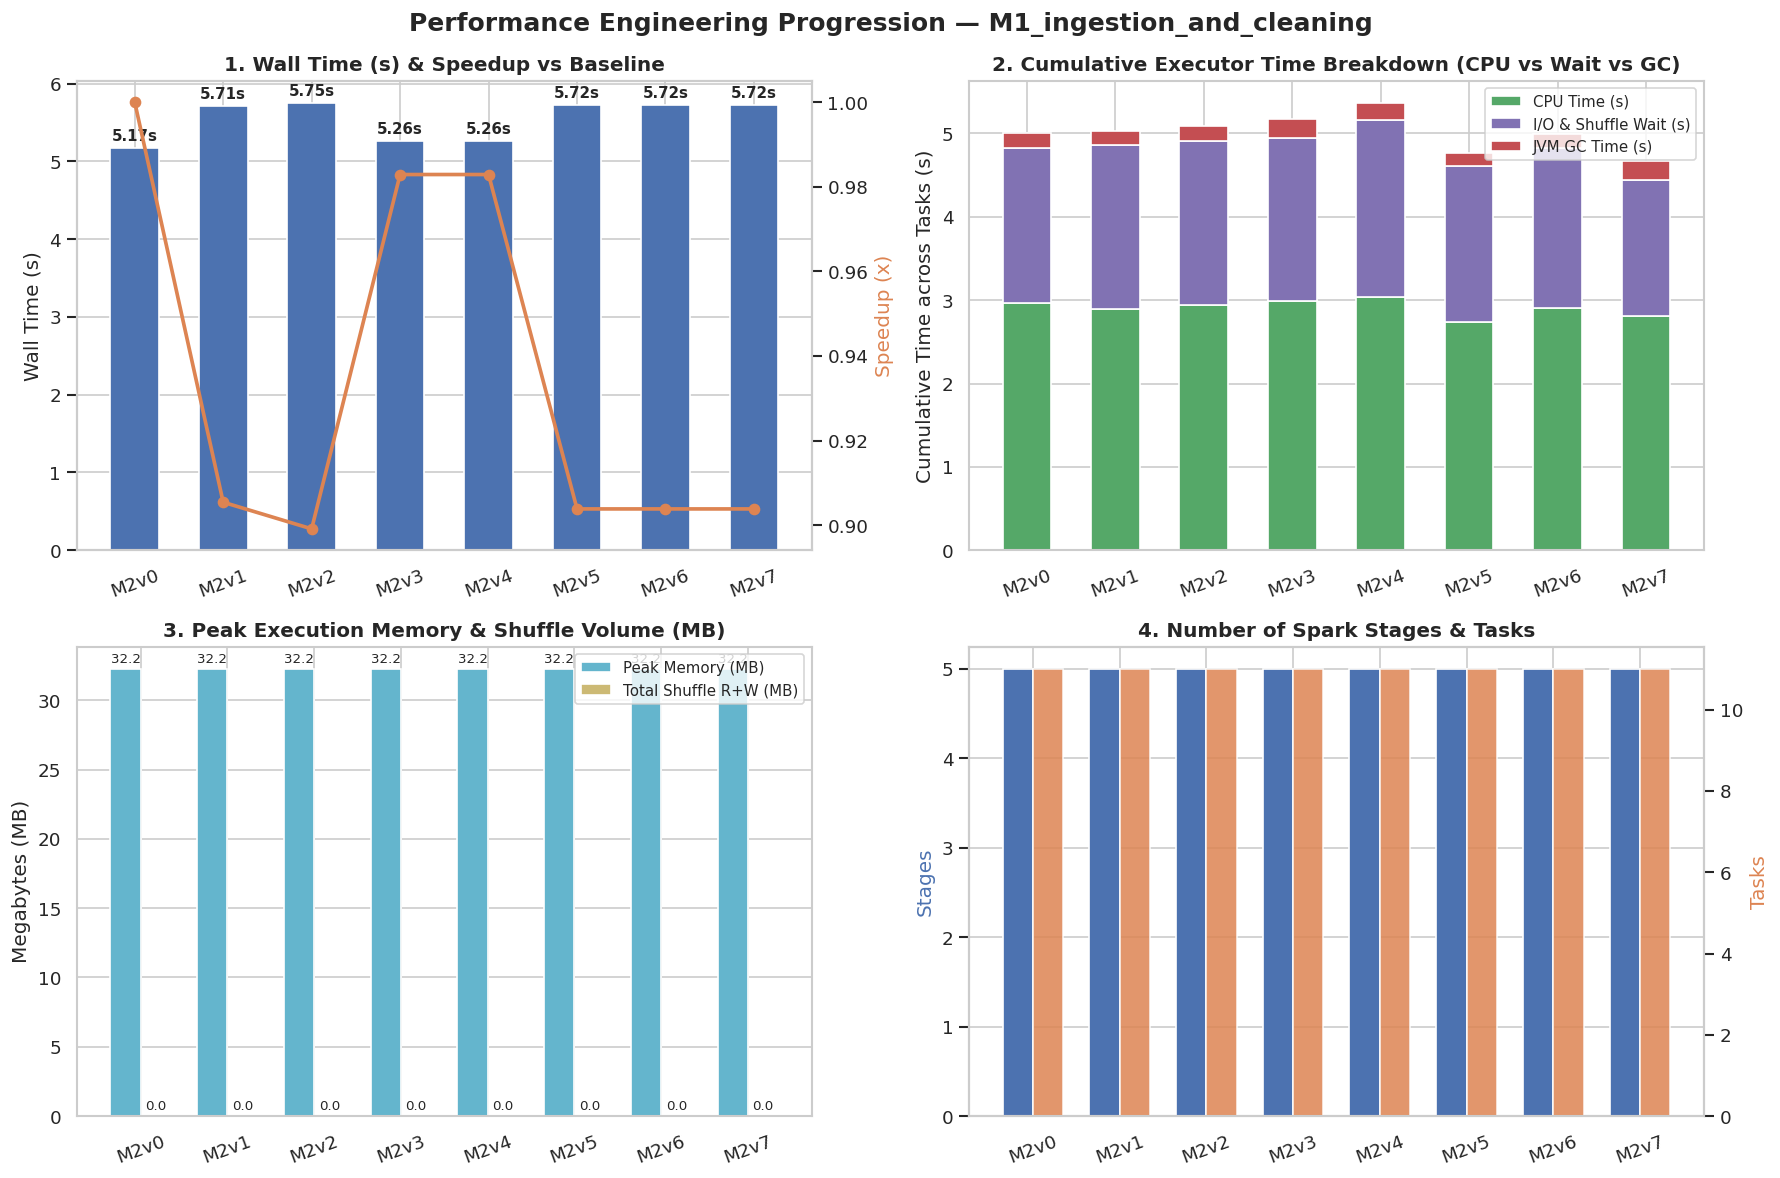

Grafico guardado em: /output/plots/benchmark_M1_ingestion_and_cleaning.png


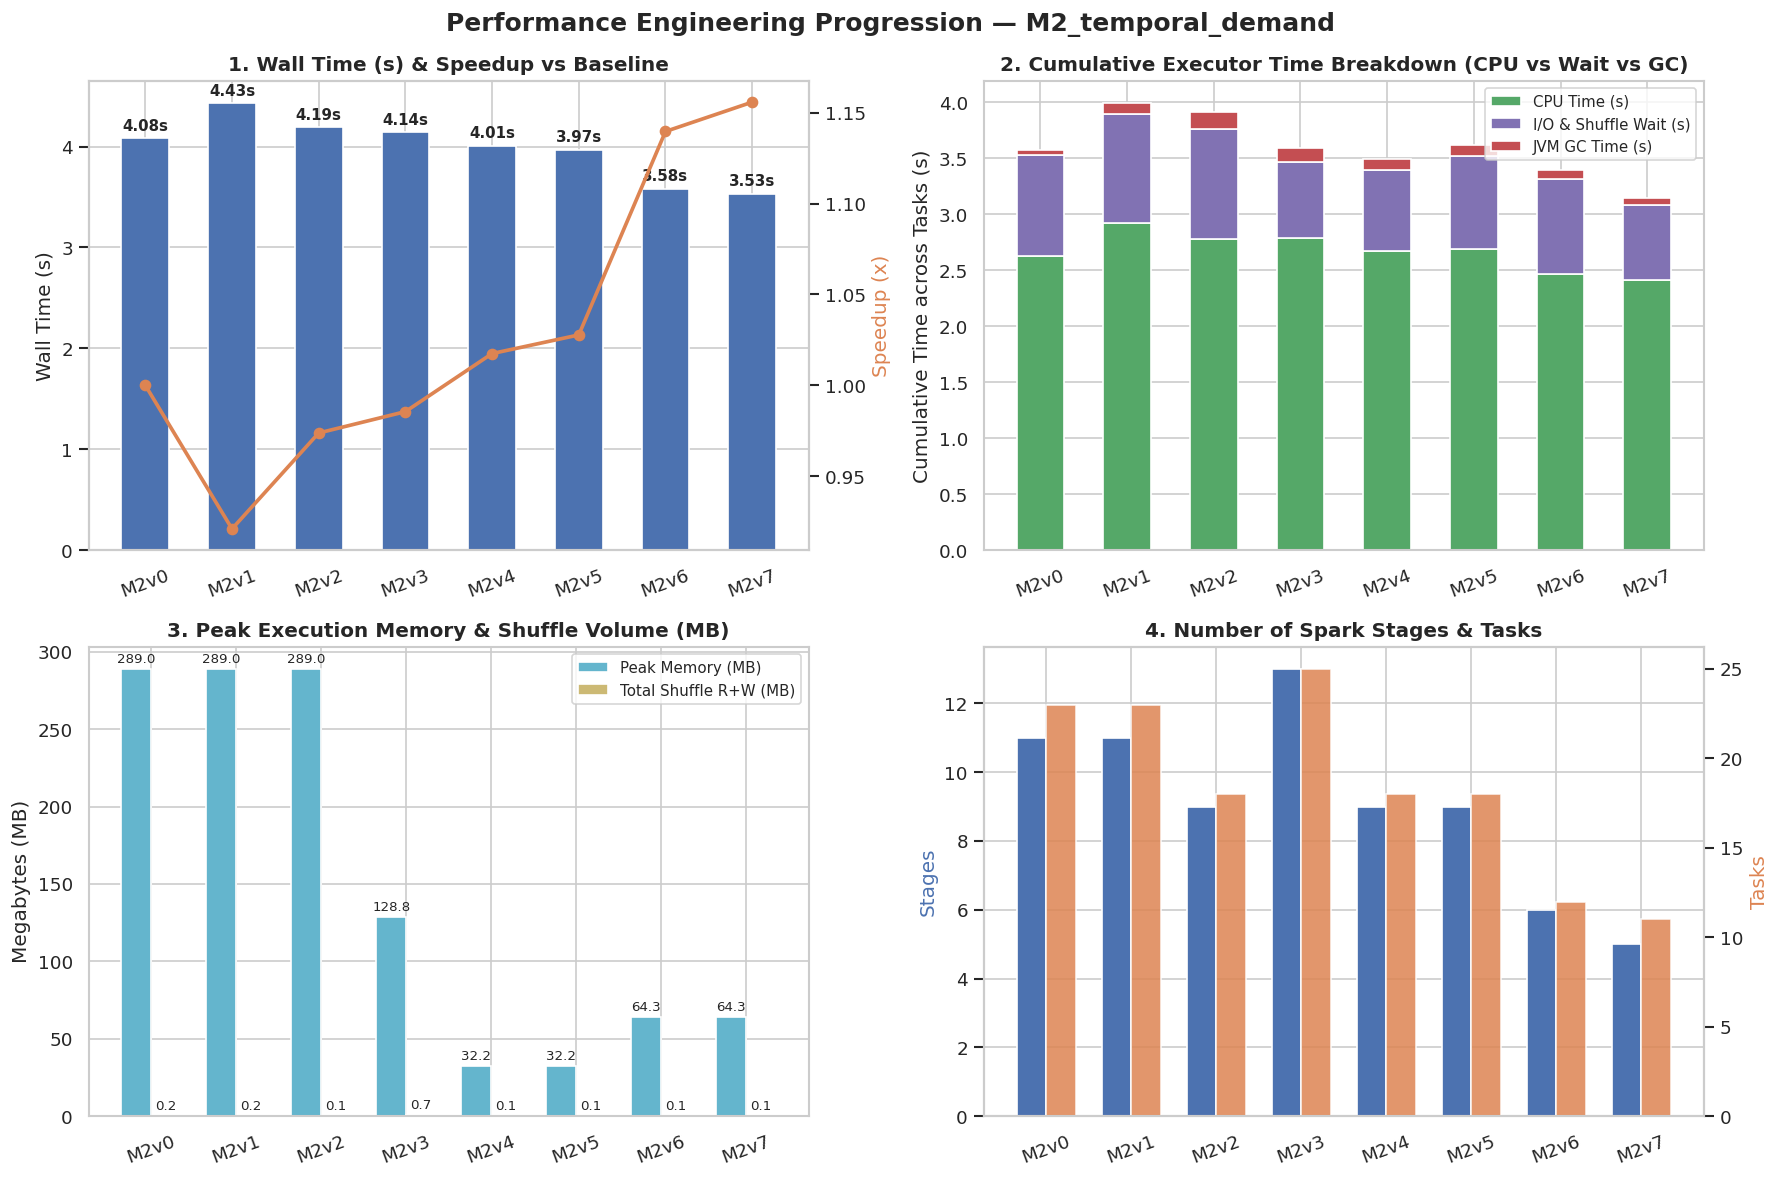

Grafico guardado em: /output/plots/benchmark_M2_temporal_demand.png


In [3]:
def plot_operation_benchmarks(df_op, op_name):
    df_op = df_op.copy().reset_index(drop=True)
    base_wall = df_op.loc[0, "wall_time_s"] if df_op.loc[0, "wall_time_s"] > 0 else 1.0
    df_op["speedup"] = base_wall / df_op["wall_time_s"].replace(0, np.nan)

    versions = df_op["version"].tolist()
    x = np.arange(len(versions))

    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    fig.suptitle(f"Performance Engineering Progression — {op_name}", fontsize=15, fontweight="bold")

    # 1. Wall Time & Speedup
    ax1 = axes[0, 0]
    bars = ax1.bar(x, df_op["wall_time_s"], color="#4C72B0", width=0.55, label="Wall Time (s)")
    ax1.set_title("1. Wall Time (s) & Speedup vs Baseline", fontweight="bold")
    ax1.set_xticks(x)
    ax1.set_xticklabels(versions, rotation=20)
    ax1.set_ylabel("Wall Time (s)")
    for bar in bars:
        h = bar.get_height()
        ax1.annotate(f"{h:.2f}s", (bar.get_x() + bar.get_width() / 2, h),
                     ha="center", va="bottom", fontsize=9, fontweight="bold", xytext=(0, 3), textcoords="offset points")

    if len(versions) > 1:
        ax1_twin = ax1.twinx()
        ax1_twin.plot(x, df_op["speedup"], color="#DD8452", marker="o", linewidth=2.2, label="Speedup (x)")
        ax1_twin.set_ylabel("Speedup (x)", color="#DD8452")
        ax1_twin.grid(False)

    # 2. Decomposicao: CPU vs GC vs I/O & Wait
    ax2 = axes[0, 1]
    ax2.bar(x, df_op["exec_cpu_s"], width=0.55, label="CPU Time (s)", color="#55A868")
    ax2.bar(x, df_op["io_wait_s"], width=0.55, bottom=df_op["exec_cpu_s"], label="I/O & Shuffle Wait (s)", color="#8172B3")
    ax2.bar(x, df_op["jvm_gc_s"], width=0.55, bottom=df_op["exec_cpu_s"] + df_op["io_wait_s"], label="JVM GC Time (s)", color="#C44E52")
    ax2.set_title("2. Cumulative Executor Time Breakdown (CPU vs Wait vs GC)", fontweight="bold")
    ax2.set_xticks(x)
    ax2.set_xticklabels(versions, rotation=20)
    ax2.set_ylabel("Cumulative Time across Tasks (s)")
    ax2.legend(loc="upper right", fontsize=9)

    # 3. Peak Execution Memory & Shuffle Volume
    ax3 = axes[1, 0]
    w = 0.35
    b1 = ax3.bar(x - w/2, df_op["peak_mem_mb"], width=w, label="Peak Memory (MB)", color="#64B5CD")
    b2 = ax3.bar(x + w/2, df_op["total_shuffle_mb"], width=w, label="Total Shuffle R+W (MB)", color="#CCB974")
    ax3.set_title("3. Peak Execution Memory & Shuffle Volume (MB)", fontweight="bold")
    ax3.set_xticks(x)
    ax3.set_xticklabels(versions, rotation=20)
    ax3.set_ylabel("Megabytes (MB)")
    ax3.legend(loc="upper right", fontsize=9)
    for bar in list(b1) + list(b2):
        h = bar.get_height()
        if h > 0:
            ax3.annotate(f"{h:.1f}", (bar.get_x() + bar.get_width() / 2, h),
                         ha="center", va="bottom", fontsize=8, xytext=(0, 2), textcoords="offset points")

    # 4. Stages & Tasks
    ax4 = axes[1, 1]
    ax4.bar(x - w/2, df_op["num_stages"], width=w, label="Stages", color="#4C72B0")
    ax4_twin = ax4.twinx()
    ax4_twin.bar(x + w/2, df_op["num_tasks"], width=w, label="Tasks", color="#DD8452", alpha=0.85)
    ax4.set_title("4. Number of Spark Stages & Tasks", fontweight="bold")
    ax4.set_xticks(x)
    ax4.set_xticklabels(versions, rotation=20)
    ax4.set_ylabel("Stages", color="#4C72B0")
    ax4_twin.set_ylabel("Tasks", color="#DD8452")
    ax4_twin.grid(False)

    plt.tight_layout()
    out_file = os.path.join(PLOTS_DIR, f"benchmark_{op_name}.png")
    plt.savefig(out_file, bbox_inches="tight")
    plt.show()
    print(f"Grafico guardado em: {out_file}")

if not df_runs.empty:
    for op_name, group in df_runs.groupby("operation", sort=False):
        plot_operation_benchmarks(group, op_name)

### 4. Detalhe por Stage (Stage Breakdown & Diagnóstico de Skew)

In [4]:
if not df_stages.empty:
    stage_display = df_stages.copy()
    stage_display["skew_Ratio"] = stage_display.apply(
        lambda r: f"{r['skew_ratio']:.1f}x (!)" if r["skew_warning"] else f"{r['skew_ratio']:.1f}x", axis=1
    )
    cols = ["version", "operation", "stage_id", "stage_name", "num_tasks",
            "run_time_ms", "cpu_time_ms", "gc_time_ms", "peak_mem_mb",
            "shuffle_read_kb", "shuffle_write_kb", "med_task_ms", "max_task_ms", "skew_Ratio"]
    display(stage_display[cols].round(2))

,version,operation,stage_id,stage_name,num_tasks,run_time_ms,cpu_time_ms,gc_time_ms,peak_mem_mb,shuffle_read_kb,shuffle_write_kb,med_task_ms,max_task_ms,skew_Ratio
0,M2v0,M1_ingestion_and_cleaning,0,M1_ingestion_and_cleaning,1,213,62,5,0.00,0.00,0.00,213,213,1.0x
1,M2v0,M1_ingestion_and_cleaning,1,M1_ingestion_and_cleaning,1,12,9,0,0.00,0.00,0.00,12,12,1.0x
2,M2v0,M1_ingestion_and_cleaning,2,M1_ingestion_and_cleaning,4,4682,2827,179,1.00,0.00,0.74,985,2125,2.2x
3,M2v0,M1_ingestion_and_cleaning,3,$anonfun$withThreadLocalCaptured$1 at Complet,4,0,0,0,0.00,0.00,0.00,0,0,1.0x
4,M2v0,M1_ingestion_and_cleaning,4,M1_ingestion_and_cleaning,1,103,64,0,32.25,0.74,0.00,103,103,1.0x
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
108,M2v7,M2_temporal_demand,5,M2_temporal_demand,1,55,47,0,0.00,0.00,0.00,55,55,1.0x
109,M2v7,M2_temporal_demand,6,M2_temporal_demand,1,619,524,24,0.00,0.00,0.00,619,619,1.0x
110,M2v7,M2_temporal_demand,7,M2_temporal_demand,4,2026,1495,32,1.00,0.00,30.14,203,1461,7.2x (!)
111,M2v7,M2_temporal_demand,8,$anonfun$withThreadLocalCaptured$1 at Complet,4,0,0,0,0.00,0.00,0.00,0,0,1.0x


### 5. Visualização Analítica do Output Parquet do M2 (`m2_temporal_demand`)

Explora os resultados produzidos pelo pipeline para o **M2 (Temporal Demand Analysis)**:
- **Heatmap de Procura Horária × Dia da Semana** nos principais *Boroughs*.
- **Curvas Horárias de Volume de Viagens, Tarifa Média ($) e Duração Média (min)**.

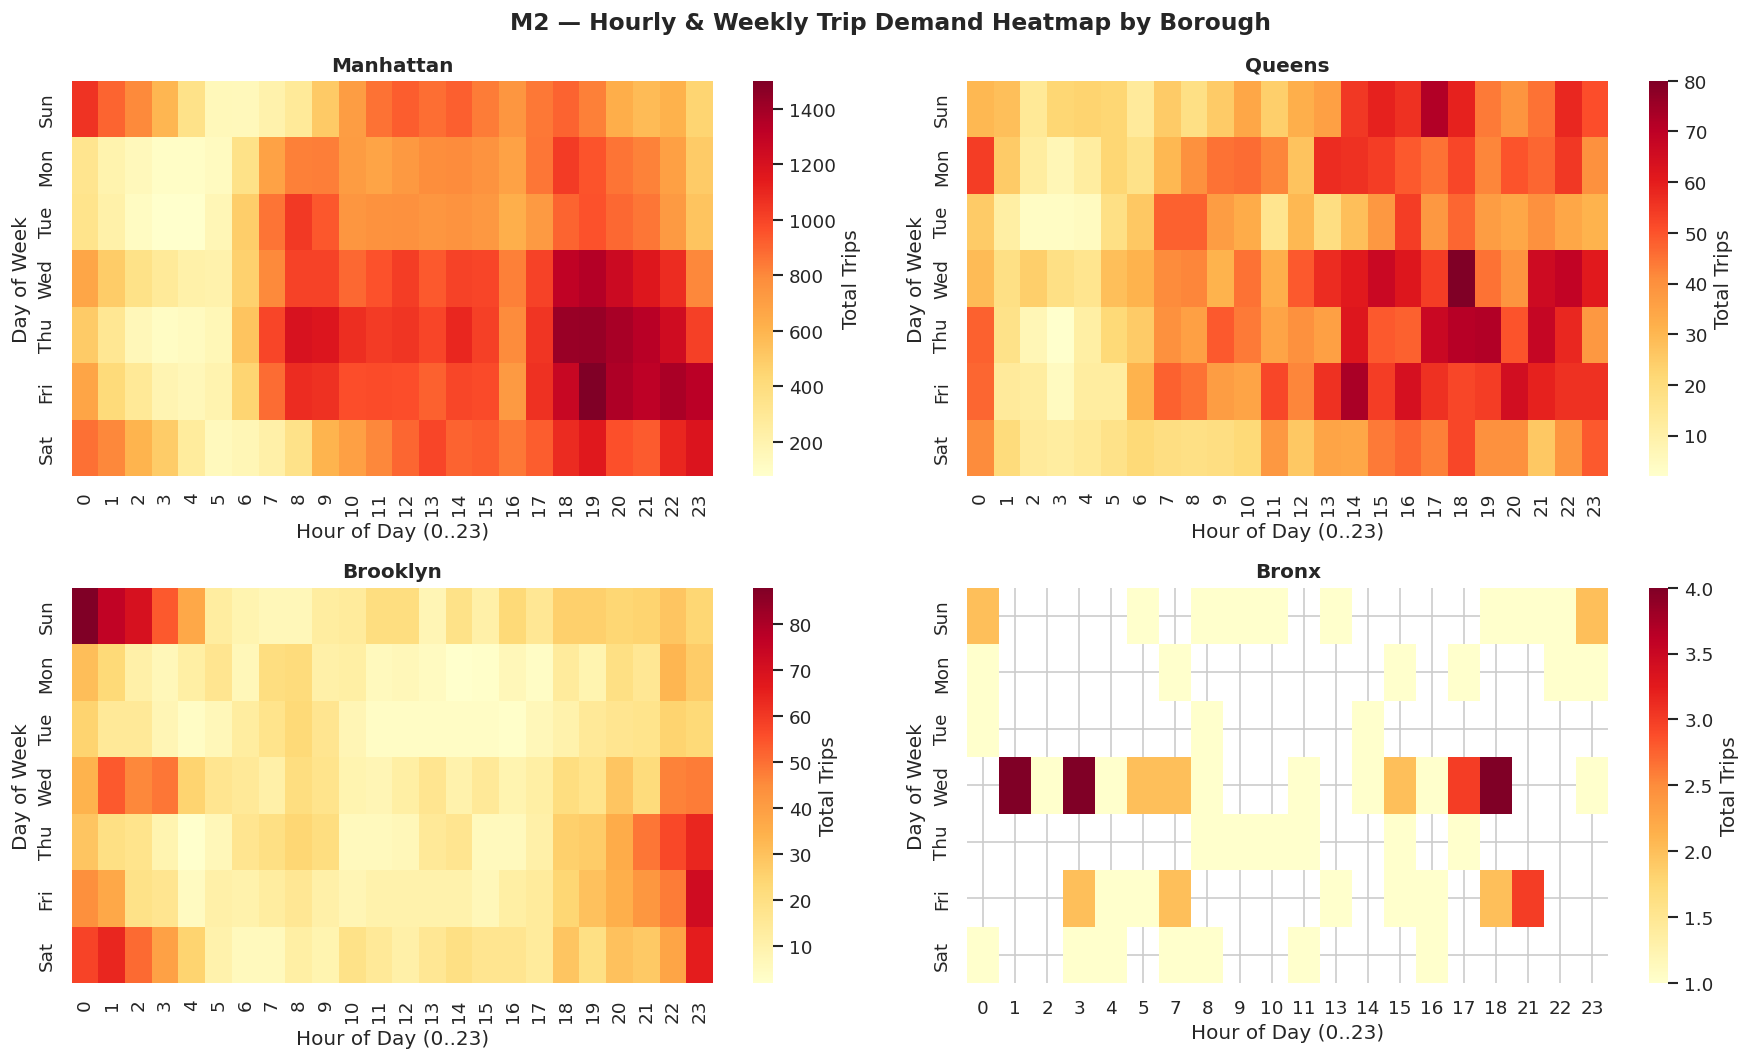

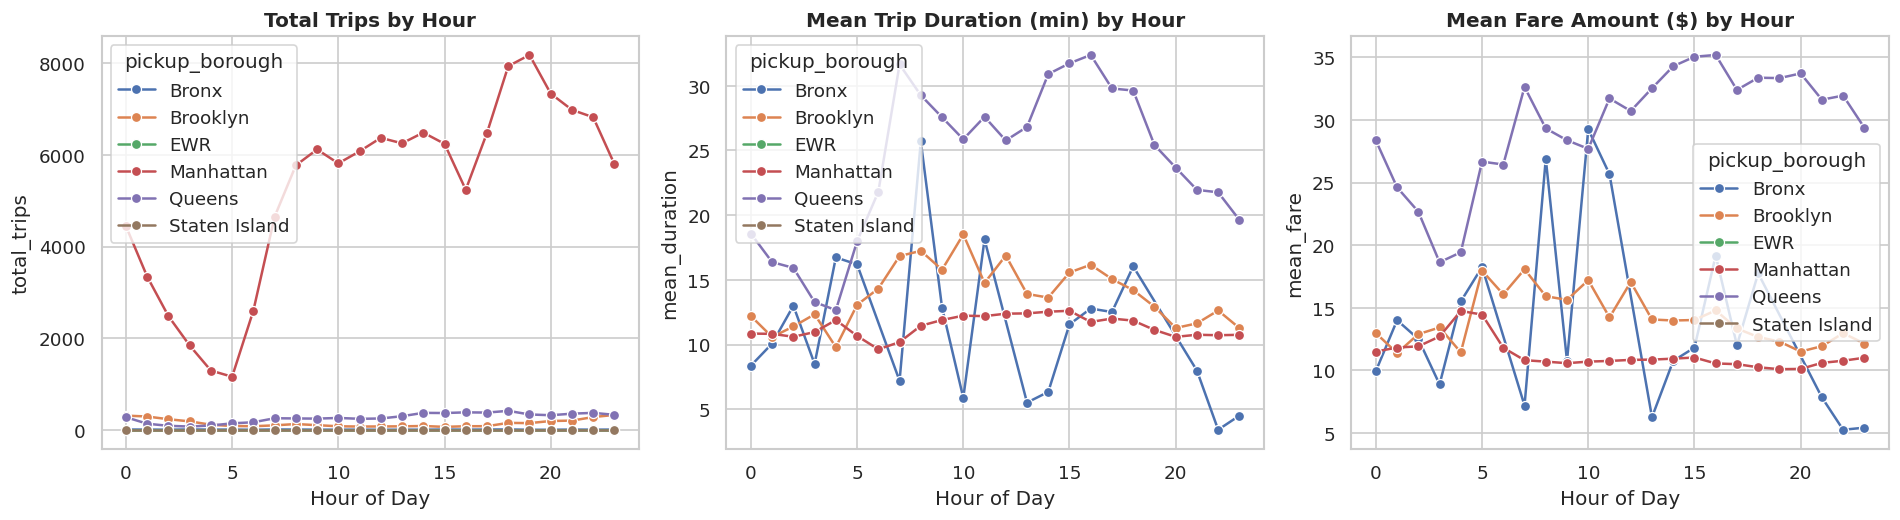

In [5]:
m2_parquet_dir = os.path.join(BASE_OUTPUT, "m2_temporal_demand")

if os.path.exists(m2_parquet_dir):
    m2_df = pd.read_parquet(m2_parquet_dir)
    day_names = {1: "Sun", 2: "Mon", 3: "Tue", 4: "Wed", 5: "Thu", 6: "Fri", 7: "Sat"}
    m2_df["day_name"] = m2_df["day_of_week"].map(day_names)

    top_boroughs = (
        m2_df.groupby("pickup_borough", observed=False)["total_trips"]
        .sum()
        .sort_values(ascending=False)
        .head(4)
        .index.tolist()
    )

    # 1. Heatmaps (Dia da Semana x Hora do Dia) para os 4 principais Boroughs
    fig, axes = plt.subplots(2, 2, figsize=(15, 9))
    fig.suptitle("M2 — Hourly & Weekly Trip Demand Heatmap by Borough", fontsize=14, fontweight="bold")
    for idx, boro in enumerate(top_boroughs):
        ax = axes[idx // 2, idx % 2]
        sub = m2_df[m2_df["pickup_borough"] == boro]
        piv = sub.pivot(index="day_of_week", columns="hour_of_day", values="total_trips").reindex(range(1, 8))
        piv.index = [day_names[d] for d in piv.index]
        sns.heatmap(piv, cmap="YlOrRd", ax=ax, cbar_kws={"label": "Total Trips"})
        ax.set_title(f"{boro}", fontweight="bold")
        ax.set_xlabel("Hour of Day (0..23)")
        ax.set_ylabel("Day of Week")
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "m2_demand_heatmap.png"), bbox_inches="tight")
    plt.show()

    # 2. Perfis Horarios (Total Trips, Mean Duration, Mean Fare)
    hourly = (
        m2_df[m2_df["pickup_borough"].isin(top_boroughs)]
        .groupby(["pickup_borough", "hour_of_day"], observed=False)
        .agg(
            total_trips=("total_trips", "sum"),
            mean_duration=("mean_trip_duration_min", "mean"),
            mean_fare=("mean_fare_amount", "mean")
        )
        .reset_index()
    )

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    sns.lineplot(data=hourly, x="hour_of_day", y="total_trips", hue="pickup_borough", marker="o", ax=axes[0])
    axes[0].set_title("Total Trips by Hour", fontweight="bold")
    axes[0].set_xlabel("Hour of Day")

    sns.lineplot(data=hourly, x="hour_of_day", y="mean_duration", hue="pickup_borough", marker="o", ax=axes[1])
    axes[1].set_title("Mean Trip Duration (min) by Hour", fontweight="bold")
    axes[1].set_xlabel("Hour of Day")

    sns.lineplot(data=hourly, x="hour_of_day", y="mean_fare", hue="pickup_borough", marker="o", ax=axes[2])
    axes[2].set_title("Mean Fare Amount ($) by Hour", fontweight="bold")
    axes[2].set_xlabel("Hour of Day")

    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "m2_hourly_profiles.png"), bbox_inches="tight")
    plt.show()
else:
    print(f"Diretoria {m2_parquet_dir} ainda nao encontrada. Corre primeiro a operacao M2.")